# Evaluación de aceptación de MBE-Bot: cálculo de los resultados de los estudiantes

Este cuaderno reproduce, a partir de la encuesta seudonimizada, **todas las cifras sobre estudiantes** que aparecen en el artículo:

| Sección del artículo | Contenido |
|---|---|
| Resultados > Participantes | Tasa de respuesta, ítem de control de atención, Tabla de características |
| Resultados > Estudiantes | Tabla de valoración (Md, RIC, % favorable, IC 95 %), α de Cronbach, figura Likert |
| Resultados > Estudiantes | Wilcoxon frente al punto neutro y análisis de sensibilidad ($n = 35$) |
| Resultados > Estudiantes | Intención de uso, correlaciones de Spearman, comparación con ChatGPT/Claude |
| Conclusiones (trabajo futuro) | Tamaño de muestra para la siguiente medición |

Al final, una **tabla de verificación** compara cada cifra calculada con la reportada en el artículo.

**Datos de entrada:** encuesta_estudiantes_seudonimizada.csv` (35 respuestas, seudónimos E01–E35; sin nombres, correos ni respuestas abiertas).

In [3]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", lambda x: f"{x:.3f}")

DATOS = Path("/content/encuesta_estudiantes_seudonimizada.csv")
SALIDA = Path("resultados")
SALIDA.mkdir(exist_ok=True)

N_POBLACION = 54      # estudiantes que usaron MBE-Bot en la sesión (censo)
UMBRAL_CONTROL = 4    # se excluye si "Estoy respondiendo aleatoriamente" > 4

# columna -> (etiqueta en el artículo, escala máxima, punto neutro, umbral favorable)
ITEMS = {
    "peou_aprender_1a7":    ("Aprender a usarla es fácil", 7, 4, 5),
    "peou_interaccion_1a7": ("Interacción clara y comprensible", 7, 4, 5),
    "peou_general_1a7":     ("En general, es fácil de usar", 7, 4, 5),
    "pu_entender_1a5":      ("Ayudó a entender los temas", 5, 3, 4),
    "claridad_1a5":         ("Claridad de las respuestas", 5, 3, 4),
    "fundamentacion_1a5":   ("Fundamentación en el curso", 5, 3, 4),
}
PEOU = ["peou_aprender_1a7", "peou_interaccion_1a7", "peou_general_1a7"]
BI_ORDEN = {"Probablemente no": 1, "Probablemente sí": 2, "Sí, definitivamente": 3}
BI_SI = ["Probablemente sí", "Sí, definitivamente"]

## 0. Carga y seudonimización de los datos

El cuaderno parte de la exportación de Microsoft Forms (`Encuesta_de_evaluaci_n___MBE-Bot_..._Sheet1.csv`), que contiene **nombre, correo y usuario** de cada estudiante. Por eso:

1. Si el archivo original está disponible, se conservan solo las variables del análisis, se asigna un seudónimo secuencial (E01–E35) y se guarda `datos/encuesta_estudiantes_seudonimizada.csv`. No se muestra ninguna fila del archivo original.
2. Si el archivo original no está (por ejemplo, al clonar el repositorio), se lee directamente el CSV seudonimizado.

**El archivo original no debe subirse al repositorio**; solo el seudonimizado. Las respuestas abiertas tampoco se conservan, porque pueden contener información identificable.

In [4]:
ORIGINAL = Path("Encuesta_de_evaluaci_n___MBE-Bot__Taller_de_Medicina_Basada_en_la_Evidencia_-_PUJ1-35_1.xlsx_-_Sheet1.csv")

# variable del análisis -> inicio del encabezado de la pregunta en el formulario
PREGUNTAS = {
    "edad": "Edad",
    "semestre": "Semestre actual",
    "veces_cursada_mbe": "¿Cuántas veces ha cursado la materia de MBE?",
    "horas_semanales_mbe": "¿Cuántas horas semanales dedica al estudio de MBE",
    "herramientas_ia": "¿Qué herramientas de IA usas actualmente",
    "frecuencia_uso_ia": "¿Con qué frecuencia usas estas herramientas",
    "confianza_llm_1a5": "¿Qué tan confiable consideras la información",
    "claridad_1a5": "¿MBE-Bot respondió de forma clara y comprensible?",
    "fundamentacion_1a5": "¿Las respuestas del chatbot estaban bien fundamentadas",
    "comparacion_generalistas": "Comparado con herramientas como ChatGPT o Claude",
    "pu_entender_1a5": "¿MBE-Bot te ayudó a entender mejor los temas del taller?",
    "bi_volveria": "¿Volverías a usar MBE-Bot para estudiar contenidos del curso?",
    "peou_aprender_1a7": "Aprender a usar esta herramienta me resulta fácil",
    "peou_interaccion_1a7": "La forma de interactuar con la herramienta es clara y comprensible",
    "control_atencion_1a7": "Estoy respondiendo aleatoriamente",
    "peou_general_1a7": "En general, encuentro fácil de usar esta herramienta",
}
NUMERICAS = ["edad", "semestre", "veces_cursada_mbe", "confianza_llm_1a5", "claridad_1a5",
             "fundamentacion_1a5", "pu_entender_1a5", "peou_aprender_1a7",
             "peou_interaccion_1a7", "control_atencion_1a7", "peou_general_1a7"]


def seudonimizar(ruta):
    crudo = pd.read_csv(ruta, dtype=str).dropna(how="all")
    columnas = {}
    for var, inicio in PREGUNTAS.items():
        # la columna de la respuesta es la que empieza con el texto de la pregunta
        # (se descartan las columnas "Puntos:" y "Comentarios:" que agrega Forms)
        candidatas = [c for c in crudo.columns if c.strip().startswith(inicio)]
        assert len(candidatas) == 1, f"No se encontró una única columna para {var}: {candidatas}"
        columnas[var] = candidatas[0]
    datos = crudo[list(columnas.values())].copy()
    datos.columns = list(columnas)
    datos = datos.apply(lambda s: s.str.strip())
    for c in NUMERICAS:
        datos[c] = pd.to_numeric(datos[c], errors="coerce").astype("Int64")
    datos.insert(0, "id", [f"E{i:02d}" for i in range(1, len(datos) + 1)])
    return datos.reset_index(drop=True)


if ORIGINAL.exists():
    todos = seudonimizar(ORIGINAL)
    DATOS.parent.mkdir(exist_ok=True)
    todos.to_csv(DATOS, index=False, encoding="utf-8")
    print(f"Archivo original encontrado: {len(todos)} respuestas seudonimizadas -> {DATOS}")
else:
    todos = pd.read_csv(DATOS)
    print(f"Archivo original no disponible: se usa {DATOS} ({len(todos)} respuestas)")

todos.head()

Archivo original no disponible: se usa /content/encuesta_estudiantes_seudonimizada.csv (35 respuestas)


,id,edad,semestre,veces_cursada_mbe,horas_semanales_mbe,herramientas_ia,frecuencia_uso_ia,confianza_llm_1a5,claridad_1a5,fundamentacion_1a5,comparacion_generalistas,pu_entender_1a5,bi_volveria,peou_aprender_1a7,peou_interaccion_1a7,control_atencion_1a7,peou_general_1a7
0,E01,21,5,1,0,ChatGPT;Claude;,Pocas veces al semestre,5,5,5,ChatGPT/Claude es mejor,4,Probablemente sí,7,7,1,7
1,E02,20,5,4,2,ChatGPT;Notebook LM;,Al menos una vez por semana,5,4,4,ChatGPT/Claude es mejor,4,Probablemente no,4,5,2,6
2,E03,20,5,1,2,Claude;,Casi todos los días,3,3,4,ChatGPT/Claude es mejor,3,Probablemente no,5,4,1,5
3,E04,21,5,1,3,ChatGPT;,Al menos una vez por semana,3,3,5,ChatGPT/Claude es mejor,3,Probablemente sí,6,5,1,5
4,E05,19,5,1,2,ChatGPT;Claude;Notebook LM;,Casi todos los días,5,2,2,ChatGPT/Claude es mejor,3,Probablemente sí,7,7,1,7


## Funciones estadísticas

- **IC de Wilson** para proporciones: adecuado con muestras pequeñas y proporciones cercanas a 0 o 1.
- **α de Cronbach** para la consistencia interna de los tres ítems de PEOU.
- **Spearman con IC 95 %**: transformación z de Fisher con el error estándar de Bonett y Wright (2000), $SE = \sqrt{(1+\rho^2/2)/(n-3)}$.
- **Wilcoxon de rangos con signo para una muestra**: $H_0$: la mediana es igual al punto neutro; se descartan las respuestas iguales al neutro y se usa la aproximación normal.
- **Ajuste de Holm** para las dos pruebas de Wilcoxon.

In [5]:
def wilson(k, n, conf=0.95):
    z = stats.norm.ppf(1 - (1 - conf) / 2)
    p = k / n
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    margen = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return max(0.0, centro - margen), min(1.0, centro + margen)


def cronbach_alpha(df):
    k = df.shape[1]
    return k / (k - 1) * (1 - df.var(ddof=1).sum() / df.sum(axis=1).var(ddof=1))


def spearman_ic(x, y):
    m = pd.concat([x, y], axis=1).dropna()
    n = len(m)
    rho, p = stats.spearmanr(m.iloc[:, 0], m.iloc[:, 1])
    se = np.sqrt((1 + rho**2 / 2) / (n - 3))
    z, zc = np.arctanh(rho), stats.norm.ppf(0.975)
    return {"n": n, "rho": rho, "ic_inf": np.tanh(z - zc * se), "ic_sup": np.tanh(z + zc * se)}


def wilcoxon_vs_neutro(valores, neutro):
    d = valores.dropna() - neutro
    d = d[d != 0]
    r = stats.wilcoxon(d, zero_method="wilcox", correction=False, method="approx")
    return {"N_distinto_neutro": len(d), "Z": abs(r.zstatistic), "p": r.pvalue}


def holm(pvals):
    orden, m = np.argsort(pvals), len(pvals)
    ajust, acum = np.empty(m), 0.0
    for rango, i in enumerate(orden):
        acum = max(acum, min(1.0, (m - rango) * pvals[i]))
        ajust[i] = acum
    return ajust


def pct(k, n):
    return 100 * k / n

## 1. Participación y exclusión por el ítem de control de atención

*Artículo, Resultados > Participantes:* de 54 estudiantes, respondieron 35 (64.8 %); 29 puntuaron entre 1 y 3 en el ítem de control, 6 puntuaron 6 o 7 y ninguno 4 o 5; se excluyen esos 6 y el análisis principal usa $n = 29$.

In [6]:
control = todos["control_atencion_1a7"].value_counts().reindex(range(1, 8), fill_value=0)
incluidos = todos[todos["control_atencion_1a7"] <= UMBRAL_CONTROL].copy()

participacion = pd.Series({
    "Población (censo)": N_POBLACION,
    "Respondieron": len(todos),
    "Tasa de respuesta (%)": round(pct(len(todos), N_POBLACION), 1),
    "Control 1-3": int(control.loc[1:3].sum()),
    "Control 4-5": int(control.loc[4:5].sum()),
    "Control 6-7": int(control.loc[6:7].sum()),
    "Excluidos": len(todos) - len(incluidos),
    "Analizados (principal)": len(incluidos),
}, dtype=object)
display(control.rename("n").to_frame().T)
participacion

control_atencion_1a7,1,2,3,4,5,6,7
n,26,2,1,0,0,2,4


,0
Población (censo),54
Respondieron,35
Tasa de respuesta (%),64.800
Control 1-3,29
Control 4-5,0
Control 6-7,6
Excluidos,6
Analizados (principal),29


## 2. Características de los participantes (Tabla de características, $n = 29$)

Las horas semanales son texto libre en el formulario (p. ej. "3 horas", "2-3 horas"): se extrae el número y, si es un rango, se toma el punto medio.

In [7]:
def horas_a_numero(x):
    nums = [float(v) for v in re.findall(r"\d+(?:[.,]\d+)?", str(x).replace(",", "."))]
    return np.mean(nums) if nums else np.nan

d = incluidos.copy()
d["horas"] = d["horas_semanales_mbe"].map(horas_a_numero)
n = len(d)

def md_ric(s):
    return f"{s.median():g} ({s.quantile(0.25):g}–{s.quantile(0.75):g})"

herr = d["herramientas_ia"].fillna("")
semanal = d["frecuencia_uso_ia"].isin(["Al menos una vez por semana", "Casi todos los días"])

caracteristicas = pd.Series({
    "Edad, M (DE) [rango]": f"{d.edad.mean():.1f} ({d.edad.std(ddof=1):.1f}) [{d.edad.min()}–{d.edad.max()}]",
    "Quinto semestre, n (%)": f"{(d.semestre == 5).sum()} ({pct((d.semestre == 5).sum(), n):.0f})",
    "Cursa MBE por primera vez, n (%)": f"{(d.veces_cursada_mbe == 1).sum()} ({pct((d.veces_cursada_mbe == 1).sum(), n):.1f})",
    "Horas semanales de estudio de MBE, Md (RIC)": md_ric(d.horas),
    "ChatGPT, n (%)": f"{herr.str.contains('ChatGPT').sum()} ({pct(herr.str.contains('ChatGPT').sum(), n):.1f})",
    "Claude, n (%)": f"{herr.str.contains('Claude').sum()} ({pct(herr.str.contains('Claude').sum(), n):.1f})",
    "NotebookLM, n (%)": f"{herr.str.contains('Notebook').sum()} ({pct(herr.str.contains('Notebook').sum(), n):.1f})",
    "Gemini, n (%)": f"{herr.str.contains('Gemini').sum()} ({pct(herr.str.contains('Gemini').sum(), n):.1f})",
    "Uso de IA para MBE al menos semanal, n (%)": f"{semanal.sum()} ({pct(semanal.sum(), n):.1f})",
    "Confianza en LLM generalistas (1-5), Md (RIC)": md_ric(d.confianza_llm_1a5),
})
caracteristicas.to_frame("Valor")

,Valor
"Edad, M (DE) [rango]",19.9 (0.7) [18–22]
"Quinto semestre, n (%)",29 (100)
"Cursa MBE por primera vez, n (%)",24 (82.8)
"Horas semanales de estudio de MBE, Md (RIC)",2 (2–3)
"ChatGPT, n (%)",27 (93.1)
"Claude, n (%)",15 (51.7)
"NotebookLM, n (%)",13 (44.8)
"Gemini, n (%)",8 (27.6)
"Uso de IA para MBE al menos semanal, n (%)",23 (79.3)
"Confianza en LLM generalistas (1-5), Md (RIC)",4 (3–4)


## 3. Valoración de MBE-Bot (Tabla de valoración, $n = 29$)

Favorable: puntuación $\geq 5$ en la escala 1–7 y $\geq 4$ en la escala 1–5. El índice PEOU es el promedio de los tres ítems de facilidad de uso.

In [8]:
def descriptivos(df):
    filas = []
    for col, (nombre, esc, neutro, umbral) in ITEMS.items():
        v = df[col].astype(float)
        k = int((v >= umbral).sum())
        lo, hi = wilson(k, len(v))
        filas.append({"Ítem": nombre, "Escala": f"1-{esc}", "n": len(v),
                      "Md": v.median(), "Q1": v.quantile(.25), "Q3": v.quantile(.75),
                      "Favorables": k, "% favorable": pct(k, len(v)),
                      "IC95 inf": 100 * lo, "IC95 sup": 100 * hi,
                      "Neutros": int((v == neutro).sum())})
    idx = df[PEOU].astype(float).mean(axis=1)
    k = int((idx >= 5).sum())
    lo, hi = wilson(k, len(idx))
    filas.append({"Ítem": "Índice PEOU", "Escala": "1-7", "n": len(idx),
                  "Md": idx.median(), "Q1": idx.quantile(.25), "Q3": idx.quantile(.75),
                  "Favorables": k, "% favorable": pct(k, len(idx)),
                  "IC95 inf": 100 * lo, "IC95 sup": 100 * hi, "Neutros": np.nan})
    return pd.DataFrame(filas).set_index("Ítem")

tabla_principal = descriptivos(incluidos)
alfa_peou = cronbach_alpha(incluidos[PEOU].astype(float))
print(f"Alfa de Cronbach (PEOU, 3 ítems): {alfa_peou:.3f}")
tabla_principal.round(1)

Alfa de Cronbach (PEOU, 3 ítems): 0.865


,Escala,n,Md,Q1,Q3,Favorables,% favorable,IC95 inf,IC95 sup,Neutros
Ítem,,,,,,,,,,
Aprender a usarla es fácil,1-7,29,6.000,5.000,7.000,27,93.100,78.000,98.100,2.000
Interacción clara y comprensible,1-7,29,6.000,6.000,7.000,25,86.200,69.400,94.500,3.000
"En general, es fácil de usar",1-7,29,7.000,6.000,7.000,27,93.100,78.000,98.100,2.000
Ayudó a entender los temas,1-5,29,4.000,4.000,5.000,22,75.900,57.900,87.800,6.000
Claridad de las respuestas,1-5,29,4.000,3.000,4.000,17,58.600,40.700,74.500,11.000
Fundamentación en el curso,1-5,29,4.000,4.000,5.000,24,82.800,65.500,92.400,4.000
Índice PEOU,1-7,29,6.300,5.700,7.000,26,89.700,73.600,96.400,NaN


### Distribución completa de las respuestas (figura Likert)

,1,2,3,4,5,6,7
Aprender a usarla es fácil,0,0,0,2,6,8,13
Interacción clara y comprensible,0,0,1,3,3,8,14
"En general, es fácil de usar",0,0,0,2,5,6,16
Ayudó a entender los temas,0,1,6,14,8,<NA>,<NA>
Claridad de las respuestas,0,1,11,11,6,<NA>,<NA>
Fundamentación en el curso,0,1,4,10,14,<NA>,<NA>


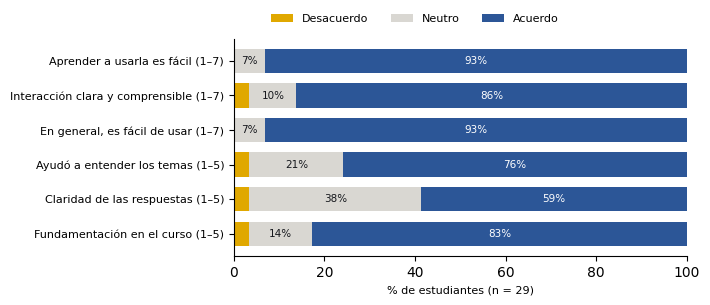

In [9]:
distribucion = pd.DataFrame({
    nombre: incluidos[col].value_counts().reindex(range(1, esc + 1), fill_value=0)
    for col, (nombre, esc, _, _) in ITEMS.items()
}).T.astype("Int64")
display(distribucion)

DIS, NEU, AGR = "#e0a800", "#d9d7d2", "#2c5697"
etiquetas, des, neu, acu = [], [], [], []
for col, (nombre, esc, neutro, umbral) in ITEMS.items():
    v = incluidos[col]
    etiquetas.append(f"{nombre} (1–{esc})")
    des.append(pct((v < neutro).sum(), len(v)))
    neu.append(pct((v == neutro).sum(), len(v)))
    acu.append(pct((v >= umbral).sum(), len(v)))
y = np.arange(len(etiquetas))[::-1]
fig, ax = plt.subplots(figsize=(7.2, 3.2))
for valores, izq, color, nombre, ctxt in [
        (des, [0] * 6, DIS, "Desacuerdo", "#15171C"),
        (neu, des, NEU, "Neutro", "#15171C"),
        (acu, [a + b for a, b in zip(des, neu)], AGR, "Acuerdo", "#FFFFFF")]:
    ax.barh(y, valores, left=izq, color=color, label=nombre, height=0.7)
    for yi, v, l in zip(y, valores, izq):
        if v >= 6:
            ax.text(l + v / 2, yi, f"{v:.0f}%", ha="center", va="center", fontsize=7.5, color=ctxt)
ax.set_yticks(y, etiquetas, fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel(f"% de estudiantes (n = {len(incluidos)})", fontsize=8)
ax.legend(ncol=3, fontsize=8, frameon=False, loc="upper center", bbox_to_anchor=(0.4, 1.16))
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
fig.tight_layout()
fig.savefig(SALIDA / "Likert_estudiantes.pdf")
fig.savefig(SALIDA / "Likert_estudiantes.png", dpi=300)
plt.show()

## 4. Contraste con el punto neutro (análisis secundario)

Wilcoxon de rangos con signo para una muestra sobre el índice PEOU (neutro = 4) y la utilidad percibida (neutro = 3), con ajuste de Holm. El resultado indica dirección frente al neutro, no magnitud.

In [10]:
def pruebas_wilcoxon(df):
    idx = df[PEOU].astype(float).mean(axis=1)
    filas = [{"Constructo": "Índice PEOU", "Neutro": 4, **wilcoxon_vs_neutro(idx, 4)},
             {"Constructo": "Utilidad percibida", "Neutro": 3,
              **wilcoxon_vs_neutro(df["pu_entender_1a5"].astype(float), 3)}]
    t = pd.DataFrame(filas).set_index("Constructo")
    t["p Holm"] = holm(t["p"].values)
    return t

wilcoxon_principal = pruebas_wilcoxon(incluidos)
wilcoxon_principal

,Neutro,N_distinto_neutro,Z,p,p Holm
Constructo,,,,,
Índice PEOU,4,29,4.687,0.000,0.000
Utilidad percibida,3,23,4.110,0.000,0.000


## 5. Análisis de sensibilidad: sin excluir por el ítem de control ($n = 35$)

In [11]:
tabla_sensibilidad = descriptivos(todos)
comparacion = pd.DataFrame({
    "% favorable n=29": tabla_principal["% favorable"],
    "% favorable n=35": tabla_sensibilidad["% favorable"],
})
comparacion["Diferencia (pp)"] = comparacion["% favorable n=35"] - comparacion["% favorable n=29"]
print("Rango de diferencias: "
      f"{comparacion['Diferencia (pp)'].min():.1f} a {comparacion['Diferencia (pp)'].max():.1f} pp")
display(comparacion.round(1))
pruebas_wilcoxon(todos)

Rango de diferencias: 1.2 a 7.1 pp


,% favorable n=29,% favorable n=35,Diferencia (pp)
Ítem,,,
Aprender a usarla es fácil,93.100,94.300,1.200
Interacción clara y comprensible,86.200,88.600,2.400
"En general, es fácil de usar",93.100,94.300,1.200
Ayudó a entender los temas,75.900,80.000,4.100
Claridad de las respuestas,58.600,65.700,7.100
Fundamentación en el curso,82.800,85.700,3.000
Índice PEOU,89.700,91.400,1.800


,Neutro,N_distinto_neutro,Z,p,p Holm
Constructo,,,,,
Índice PEOU,4,35,5.163,0.000,0.000
Utilidad percibida,3,29,4.663,0.000,0.000


## 6. Intención de uso

In [12]:
def intencion(df):
    n = len(df)
    t = df["bi_volveria"].value_counts().reindex(list(BI_ORDEN)).to_frame("n")
    t["%"] = pct(t["n"], n)
    k = int(df["bi_volveria"].isin(BI_SI).sum())
    lo, hi = wilson(k, n)
    return t, pct(k, n), (100 * lo, 100 * hi)

bi_tabla, bi_pct, bi_ic = intencion(incluidos)
display(bi_tabla.round(1))
print(f"Volvería a usarla: {bi_pct:.1f} % (IC 95 % [{bi_ic[0]:.1f}, {bi_ic[1]:.1f}])")

,n,%
bi_volveria,,
Probablemente no,4,13.800
Probablemente sí,21,72.400
"Sí, definitivamente",4,13.800


Volvería a usarla: 86.2 % (IC 95 % [69.4, 94.5])


## 7. Relaciones entre constructos del TAM (Spearman con IC 95 %)

La intención de uso se codifica como ordinal: Probablemente no = 1, Probablemente sí = 2, Sí, definitivamente = 3.

In [13]:
def correlaciones(df):
    d = df.copy()
    d["peou_indice"] = d[PEOU].astype(float).mean(axis=1)
    d["bi_ordinal"] = d["bi_volveria"].map(BI_ORDEN)
    pares = [("Intención de uso – Facilidad de uso", "bi_ordinal", "peou_indice"),
             ("Intención de uso – Utilidad percibida", "bi_ordinal", "pu_entender_1a5"),
             ("Utilidad percibida – Claridad", "pu_entender_1a5", "claridad_1a5")]
    return pd.DataFrame({nombre: spearman_ic(d[a].astype(float), d[b].astype(float))
                         for nombre, a, b in pares}).T

corr_principal = correlaciones(incluidos)
corr_sensibilidad = correlaciones(todos)
display(corr_principal.round(2))
corr_sensibilidad.round(2)

,n,rho,ic_inf,ic_sup
Intención de uso – Facilidad de uso,29.000,0.480,0.120,0.730
Intención de uso – Utilidad percibida,29.000,0.480,0.110,0.730
Utilidad percibida – Claridad,29.000,0.470,0.100,0.720


,n,rho,ic_inf,ic_sup
Intención de uso – Facilidad de uso,35.000,0.290,-0.060,0.570
Intención de uso – Utilidad percibida,35.000,0.390,0.060,0.650
Utilidad percibida – Claridad,35.000,0.430,0.100,0.680


## 8. Comparación con herramientas generalistas

In [14]:
comp = incluidos["comparacion_generalistas"].value_counts()
comp_pct = pct(comp, len(incluidos))
display(pd.DataFrame({"n": comp, "%": comp_pct.round(1)}))

prefieren_gen = incluidos[incluidos["comparacion_generalistas"] == "ChatGPT/Claude es mejor"]
volverian = int(prefieren_gen["bi_volveria"].isin(BI_SI).sum())
print(f"De {len(prefieren_gen)} que prefieren ChatGPT/Claude, {volverian} volverían a usar MBE-Bot "
      f"({pct(volverian, len(prefieren_gen)):.1f} %)")

,n,%
comparacion_generalistas,,
ChatGPT/Claude es mejor,19,65.500
MBE-Bot es mejor,5,17.200
Son similares,5,17.200


De 19 que prefieren ChatGPT/Claude, 15 volverían a usar MBE-Bot (78.9 %)


## 9. Tamaño de muestra para la siguiente medición (trabajo futuro)

$n = z^2\,p(1-p)/m^2$, con $p$ = proporción favorable del ítem con menor valoración (claridad) y un margen de $\pm 10$ puntos porcentuales.

In [15]:
z = stats.norm.ppf(0.975)
p_claridad = tabla_principal.loc["Claridad de las respuestas", "% favorable"] / 100
tamano = pd.DataFrame([{"p supuesta": p, "margen (pp)": 100 * m,
                        "n requerido": int(np.ceil(z**2 * p * (1 - p) / m**2))}
                       for p in (round(p_claridad, 3), 0.5) for m in (0.10, 0.15)])
tamano

,p supuesta,margen (pp),n requerido
0,0.586,10.000,94
1,0.586,15.000,42
2,0.500,10.000,97
3,0.500,15.000,43


## 10. Tabla de verificación frente al artículo

Cada fila compara una cifra reportada en el artículo con la calculada en este cuaderno, redondeada a la misma precisión.

In [16]:
tp, ts = tabla_principal, tabla_sensibilidad
fav = lambda t, i: round(t.loc[i, "% favorable"], 1)
ic = lambda t, i: f"[{t.loc[i, 'IC95 inf']:.1f}, {t.loc[i, 'IC95 sup']:.1f}]"
cr = lambda t, i, c: round(t.loc[i, c], 2)

verificacion = [
    ("Tasa de respuesta (%)", 64.8, participacion["Tasa de respuesta (%)"]),
    ("Excluidos por control", 6, participacion["Excluidos"]),
    ("Analizados", 29, participacion["Analizados (principal)"]),
    ("Edad, M (DE) [rango]", "19.9 (0.7) [18–22]", caracteristicas["Edad, M (DE) [rango]"]),
    ("Cursa MBE por primera vez", "24 (82.8)", caracteristicas["Cursa MBE por primera vez, n (%)"]),
    ("Horas semanales, Md (RIC)", "2 (2–3)", caracteristicas["Horas semanales de estudio de MBE, Md (RIC)"]),
    ("ChatGPT", "27 (93.1)", caracteristicas["ChatGPT, n (%)"]),
    ("Claude", "15 (51.7)", caracteristicas["Claude, n (%)"]),
    ("NotebookLM", "13 (44.8)", caracteristicas["NotebookLM, n (%)"]),
    ("Gemini", "8 (27.6)", caracteristicas["Gemini, n (%)"]),
    ("Uso semanal de IA", "23 (79.3)", caracteristicas["Uso de IA para MBE al menos semanal, n (%)"]),
    ("Confianza en LLM, Md (RIC)", "4 (3–4)", caracteristicas["Confianza en LLM generalistas (1-5), Md (RIC)"]),
    ("Alfa de Cronbach PEOU", 0.87, round(alfa_peou, 2)),
    ("Aprender a usarla: % fav [IC]", "93.1 [78.0, 98.1]", f"{fav(tp, 'Aprender a usarla es fácil')} {ic(tp, 'Aprender a usarla es fácil')}"),
    ("Interacción: % fav [IC]", "86.2 [69.4, 94.5]", f"{fav(tp, 'Interacción clara y comprensible')} {ic(tp, 'Interacción clara y comprensible')}"),
    ("En general fácil: % fav [IC]", "93.1 [78.0, 98.1]", f"{fav(tp, 'En general, es fácil de usar')} {ic(tp, 'En general, es fácil de usar')}"),
    ("Índice PEOU: % fav [IC]", "89.7 [73.6, 96.4]", f"{fav(tp, 'Índice PEOU')} {ic(tp, 'Índice PEOU')}"),
    ("Índice PEOU: Md (RIC)", "6.33 (5.67–7.00)", f"{tp.loc['Índice PEOU','Md']:.2f} ({tp.loc['Índice PEOU','Q1']:.2f}–{tp.loc['Índice PEOU','Q3']:.2f})"),
    ("PU: % fav [IC]", "75.9 [57.9, 87.8]", f"{fav(tp, 'Ayudó a entender los temas')} {ic(tp, 'Ayudó a entender los temas')}"),
    ("Claridad: % fav [IC]", "58.6 [40.7, 74.5]", f"{fav(tp, 'Claridad de las respuestas')} {ic(tp, 'Claridad de las respuestas')}"),
    ("Claridad: respuestas neutras", 11, int(tp.loc["Claridad de las respuestas", "Neutros"])),
    ("Fundamentación: % fav [IC]", "82.8 [65.5, 92.4]", f"{fav(tp, 'Fundamentación en el curso')} {ic(tp, 'Fundamentación en el curso')}"),
    ("Wilcoxon PEOU |Z| (N)", "4.69 (29)", f"{wilcoxon_principal.loc['Índice PEOU','Z']:.2f} ({wilcoxon_principal.loc['Índice PEOU','N_distinto_neutro']})"),
    ("Wilcoxon PU |Z| (N)", "4.11 (23)", f"{wilcoxon_principal.loc['Utilidad percibida','Z']:.2f} ({wilcoxon_principal.loc['Utilidad percibida','N_distinto_neutro']})"),
    ("Wilcoxon p Holm < 0.001", True, bool((wilcoxon_principal["p Holm"] < 0.001).all())),
    ("Sensibilidad: rango de diferencias (pp)", "1.2 a 7.1", f"{comparacion['Diferencia (pp)'].min():.1f} a {comparacion['Diferencia (pp)'].max():.1f}"),
    ("Sensibilidad: claridad n=35", 65.7, fav(ts, "Claridad de las respuestas")),
    ("Sensibilidad: PU n=35", 80.0, fav(ts, "Ayudó a entender los temas")),
    ("Intención de uso [IC]", "86.2 [69.4, 94.5]", f"{bi_pct:.1f} [{bi_ic[0]:.1f}, {bi_ic[1]:.1f}]"),
    ("Sí, definitivamente (%)", 13.8, round(bi_tabla.loc["Sí, definitivamente", "%"], 1)),
    ("Probablemente sí (%)", 72.4, round(bi_tabla.loc["Probablemente sí", "%"], 1)),
    ("Probablemente no (%)", 13.8, round(bi_tabla.loc["Probablemente no", "%"], 1)),
    ("rho BI–PEOU [IC], n=29", "0.48 [0.12, 0.73]", f"{cr(corr_principal,'Intención de uso – Facilidad de uso','rho'):.2f} [{cr(corr_principal,'Intención de uso – Facilidad de uso','ic_inf'):.2f}, {cr(corr_principal,'Intención de uso – Facilidad de uso','ic_sup'):.2f}]"),
    ("rho BI–PU [IC], n=29", "0.48 [0.11, 0.73]", f"{cr(corr_principal,'Intención de uso – Utilidad percibida','rho'):.2f} [{cr(corr_principal,'Intención de uso – Utilidad percibida','ic_inf'):.2f}, {cr(corr_principal,'Intención de uso – Utilidad percibida','ic_sup'):.2f}]"),
    ("rho PU–Claridad [IC], n=29", "0.47 [0.10, 0.72]", f"{cr(corr_principal,'Utilidad percibida – Claridad','rho'):.2f} [{cr(corr_principal,'Utilidad percibida – Claridad','ic_inf'):.2f}, {cr(corr_principal,'Utilidad percibida – Claridad','ic_sup'):.2f}]"),
    ("rho BI–PU [IC], n=35", "0.39 [0.06, 0.65]", f"{cr(corr_sensibilidad,'Intención de uso – Utilidad percibida','rho'):.2f} [{cr(corr_sensibilidad,'Intención de uso – Utilidad percibida','ic_inf'):.2f}, {cr(corr_sensibilidad,'Intención de uso – Utilidad percibida','ic_sup'):.2f}]"),
    ("rho PU–Claridad [IC], n=35", "0.43 [0.10, 0.68]", f"{cr(corr_sensibilidad,'Utilidad percibida – Claridad','rho'):.2f} [{cr(corr_sensibilidad,'Utilidad percibida – Claridad','ic_inf'):.2f}, {cr(corr_sensibilidad,'Utilidad percibida – Claridad','ic_sup'):.2f}]"),
    ("rho BI–PEOU [IC], n=35", "0.29 [-0.06, 0.57]", f"{cr(corr_sensibilidad,'Intención de uso – Facilidad de uso','rho'):.2f} [{cr(corr_sensibilidad,'Intención de uso – Facilidad de uso','ic_inf'):.2f}, {cr(corr_sensibilidad,'Intención de uso – Facilidad de uso','ic_sup'):.2f}]"),
    ("Prefieren ChatGPT/Claude (%)", 65.5, round(comp_pct.get("ChatGPT/Claude es mejor"), 1)),
    ("Los consideran similares (%)", 17.2, round(comp_pct.get("Son similares"), 1)),
    ("Prefieren MBE-Bot (%)", 17.2, round(comp_pct.get("MBE-Bot es mejor"), 1)),
    ("De los que prefieren generalistas, volverían", "15 de 19 (78.9)", f"{volverian} de {len(prefieren_gen)} ({pct(volverian, len(prefieren_gen)):.1f})"),
    ("Tamaño de muestra, margen ±10 pp", 94, int(tamano.query("`margen (pp)` == 10")["n requerido"].iloc[0])),
]
tabla_verif = pd.DataFrame(verificacion, columns=["Cifra", "Artículo", "Calculado"])
tabla_verif["Coincide"] = tabla_verif["Artículo"].astype(str) == tabla_verif["Calculado"].astype(str)
tabla_verif.to_csv(SALIDA / "verificacion_articulo.csv", index=False)
print(f"Coinciden {tabla_verif['Coincide'].sum()} de {len(tabla_verif)} cifras")
tabla_verif

Coinciden 43 de 43 cifras


,Cifra,Artículo,Calculado,Coincide
0,Tasa de respuesta (%),64.800,64.800,True
1,Excluidos por control,6,6,True
2,Analizados,29,29,True
3,"Edad, M (DE) [rango]",19.9 (0.7) [18–22],19.9 (0.7) [18–22],True
4,Cursa MBE por primera vez,24 (82.8),24 (82.8),True
5,"Horas semanales, Md (RIC)",2 (2–3),2 (2–3),True
6,ChatGPT,27 (93.1),27 (93.1),True
7,Claude,15 (51.7),15 (51.7),True
8,NotebookLM,13 (44.8),13 (44.8),True
9,Gemini,8 (27.6),8 (27.6),True
